# **DAY 3 PRACTICAL TASK**

In [45]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
import pandas as pd
import seaborn as sns
from sklearn.model_selection import GridSearchCV
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, roc_auc_score


Task 1
Load breast cancer classification dataset from scikit-learn

In [46]:
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['target'] = cancer.target
print(df.head())
print("Dataset shape:", df.shape)

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

**OBSERVATION**

Here I first imported breast_cancer dataset from Scikit-learn and loaded the dataset. The dataset contains 569 observations and 30 input features also one target variable. and now the dataset is ready to train and evaluate classification models.

Task 2
Train a Desicion Tree, Random Forest and Gradient Boosting model (use the same split and metric for a fair comparison)

In [47]:
X = df.drop('target', axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.7,
    random_state=42,
    stratify=y
)
print(X_train.shape, X_test.shape)

(398, 30) (171, 30)


In [49]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=10,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

results = {}
predictions = {}

for name, model in models.items():
  
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  predictions[name] = y_pred
  accuracy = accuracy_score(y_test, y_pred)
  results[name] = accuracy
  print(f"{name} Accuracy: {accuracy:.3f}")

Decision Tree Accuracy: 0.918
Random Forest Accuracy: 0.930
Gradient Boosting Accuracy: 0.942


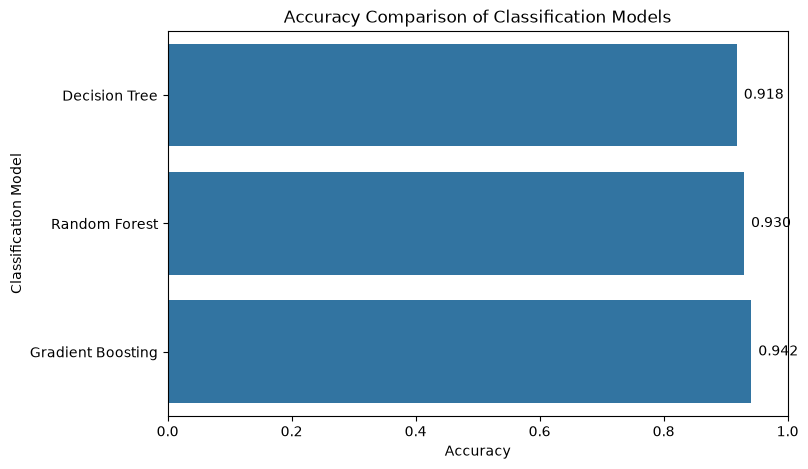

In [50]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=list(results.values()),
    y=list(results.keys())
)

plt.title('Accuracy Comparison of Classification Models')
plt.xlabel('Accuracy')
plt.ylabel('Classification Model')

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=5)

plt.xlim(0, 1)
plt.show()

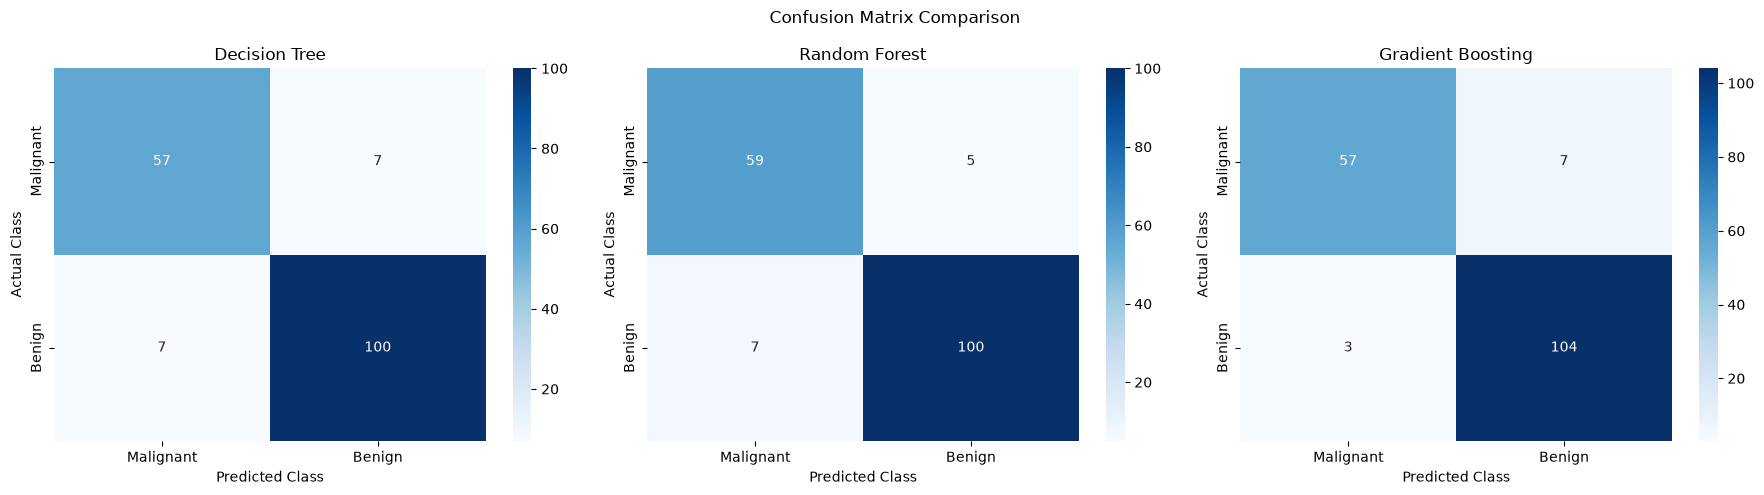

In [52]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Malignant', 'Benign'],
        yticklabels=['Malignant', 'Benign'],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel('Predicted Class')
    ax.set_ylabel('Actual Class')

plt.suptitle('Confusion Matrix Comparison')
plt.tight_layout()
plt.show()

**OBSERVATION**

So for the three classification model - Decision Tree, Random Forest and Gradient Boosting were trained and evaluated using the same train-test split with random_state=42 and stratified sampling to ensure a fair comparison between three models. The accuracy result shows that Gradient Boosting achieved accuracy of 0.942 followed by Random Forest at 0.930 and Decision Tree at 0.918.

Next Thing was the confusion matrices providing further insight into predictions and there we can find:
- Decision Tree: Correctly classified 57 malignant and 100 benign cases, with 14 incorrect predictions.
- Random Forest: Correctly classified 59 malignant and 100 benign cases, with 12 incorrect predictions.
- Gradient Boosting: Correctly classified 57 malignant and 104 benign cases, with 10 incorrect predictions.

From overall performance Gradient Boosting Achieved best performance among three models 


Task 3 
Tune Random Forest hyperparameters and report the best combination

In [53]:
rf = RandomForestClassifier(random_state=42, n_jobs=-1)
params = {
    'max_depth': [2, 3],
    'min_samples_leaf': [5, 10],
    'n_estimators': [10, 25, 30]
}

grid_search = GridSearchCV(
    estimator=rf,
    param_grid=params,
    cv=4,
    n_jobs=-1,
    verbose=1,
    scoring='accuracy'
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV Accuracy:", grid_search.best_score_)

best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Fitting 4 folds for each of 12 candidates, totalling 48 fits
Best Parameters: {'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 30}
Best CV Accuracy: 0.9623484848484849
Accuracy: 0.9298245614035088


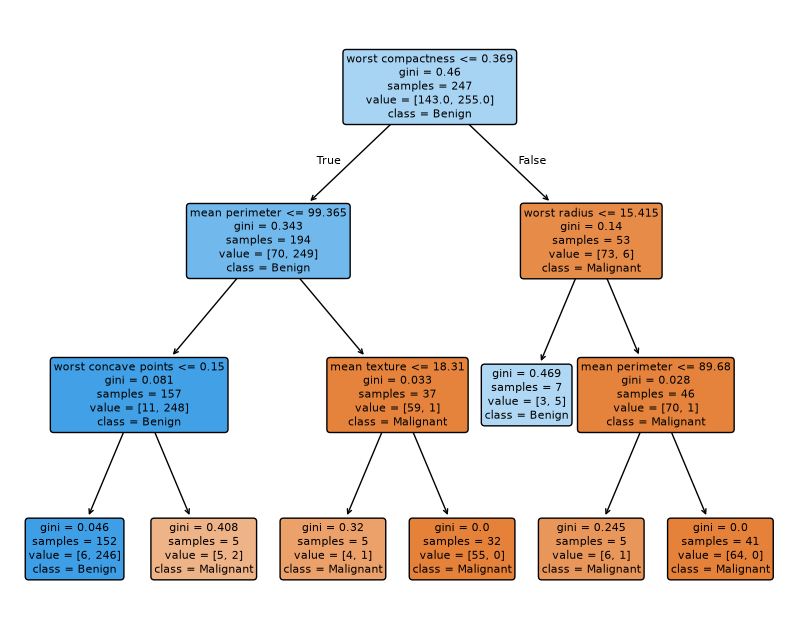

In [59]:
plt.figure(figsize=(10, 8))

plot_tree(
    best_model.estimators_[5],
    feature_names=X.columns,
    class_names=['Malignant', 'Benign'],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.show()

**OBSERVATION**

Here GridSearchCV was used to find the best hyperparameters for the Random Forest model. 
The best combination was
- max_depth: 3
- min_samples_leaf: 5
- n_estimators: 30. 

The best cross-validation accuracy was 0.9623484848484849, and the test accuracy was 0.9298245614035088. Compared to the original Random Forest model the tuned model achieved almost the same test accuracy. This showed that the hyperparameter tuning helped to find the best parameter combination but did not significantly improve the test accuracy.

Task 4
Compare ROC-AUC, F1 or another task-appropriate metric for all models

In [60]:
metric_results = {}

for name, model in models.items():

    y_pred = predictions[name]
    y_prob = model.predict_proba(X_test)[:, 1]

    metric_results[name] = {
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    }

    print(f"{name} F1-Score: {metric_results[name]['F1-Score']:.3f}")
    print(f"{name} ROC-AUC: {metric_results[name]['ROC-AUC']:.3f}")

Decision Tree F1-Score: 0.935
Decision Tree ROC-AUC: 0.913
Random Forest F1-Score: 0.943
Random Forest ROC-AUC: 0.982
Gradient Boosting F1-Score: 0.954
Gradient Boosting ROC-AUC: 0.990


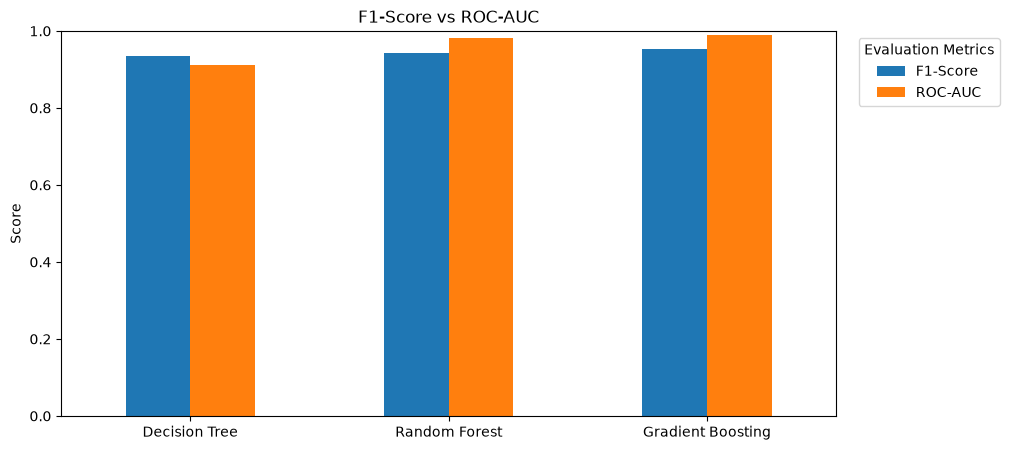

In [61]:
metric_df = pd.DataFrame(metric_results).T
metric_df
metric_df.plot(kind='bar', figsize=(10, 5))

plt.title('F1-Score vs ROC-AUC')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title='Evaluation Metrics',bbox_to_anchor=(1.02, 1))
plt.show()



**OBSERVATION**

The results show that Gradient Boosting performed the best, with the highest F1-score of 0.954 and ROC-AUC of 0.990. Random Forest also performed well, with an F1-score of 0.943 and ROC-AUC of 0.982. Decision Tree had the lowest scores, with an F1-score of 0.935 and ROC-AUC of 0.913. Overall, Gradient Boosting showed the best performance among the three models, while all three models achieved good results.